# ВШЭ 2026: Математические методы анализа данных

## Семинар 9: Обнаружение аномалий и кластеризация

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import datasets
import warnings
warnings.filterwarnings("ignore")

# Содержание

## Обнаружение аномалий
- [Метод опорных векторов одного класса](#one-class_svm)
- [Изолирующий лес](#isolation_forest)
- [CUSUM](#cumsum)

## Кластеризация
- [k-Means](#k-means)
- [DBSCAN](#dbscan)
- [Иерархическая кластеризация](#Hierarchical-clustering)


## Подготовка данных и разведочный анализ (EDA)

In [2]:
data = pd.read_csv('https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv', sep=';')
# data = pd.read_csv('winequality-white.csv', sep=';')
data.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [3]:
data.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000
mean,6.854788,0.278241,0.334192,6.391415,0.045772,35.308085,138.360657,0.994027,3.188267,0.489847,10.514267,5.877909
std,0.843868,0.100795,0.121020,5.072058,0.021848,17.007137,42.498065,0.002991,0.151001,0.114126,1.230621,0.885639
min,3.800000,0.080000,0.000000,0.600000,0.009000,2.000000,9.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.300000,0.210000,0.270000,1.700000,0.036000,23.000000,108.000000,0.991723,3.090000,0.410000,9.500000,5.000000
50%,6.800000,0.260000,0.320000,5.200000,0.043000,34.000000,134.000000,0.993740,3.180000,0.470000,10.400000,6.000000
75%,7.300000,0.320000,0.390000,9.900000,0.050000,46.000000,167.000000,0.996100,3.280000,0.550000,11.400000,6.000000
max,14.200000,1.100000,1.660000,65.800000,0.346000,289.000000,440.000000,1.038980,3.820000,1.080000,14.200000,9.000000


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4898 entries, 0 to 4897
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         4898 non-null   float64
 1   volatile acidity      4898 non-null   float64
 2   citric acid           4898 non-null   float64
 3   residual sugar        4898 non-null   float64
 4   chlorides             4898 non-null   float64
 5   free sulfur dioxide   4898 non-null   float64
 6   total sulfur dioxide  4898 non-null   float64
 7   density               4898 non-null   float64
 8   pH                    4898 non-null   float64
 9   sulphates             4898 non-null   float64
 10  alcohol               4898 non-null   float64
 11  quality               4898 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 459.3 KB


array([[<Axes: title={'center': 'fixed acidity'}>,
        <Axes: title={'center': 'volatile acidity'}>,
        <Axes: title={'center': 'citric acid'}>],
       [<Axes: title={'center': 'residual sugar'}>,
        <Axes: title={'center': 'chlorides'}>,
        <Axes: title={'center': 'free sulfur dioxide'}>],
       [<Axes: title={'center': 'total sulfur dioxide'}>,
        <Axes: title={'center': 'density'}>,
        <Axes: title={'center': 'pH'}>],
       [<Axes: title={'center': 'sulphates'}>,
        <Axes: title={'center': 'alcohol'}>,
        <Axes: title={'center': 'quality'}>]], dtype=object)

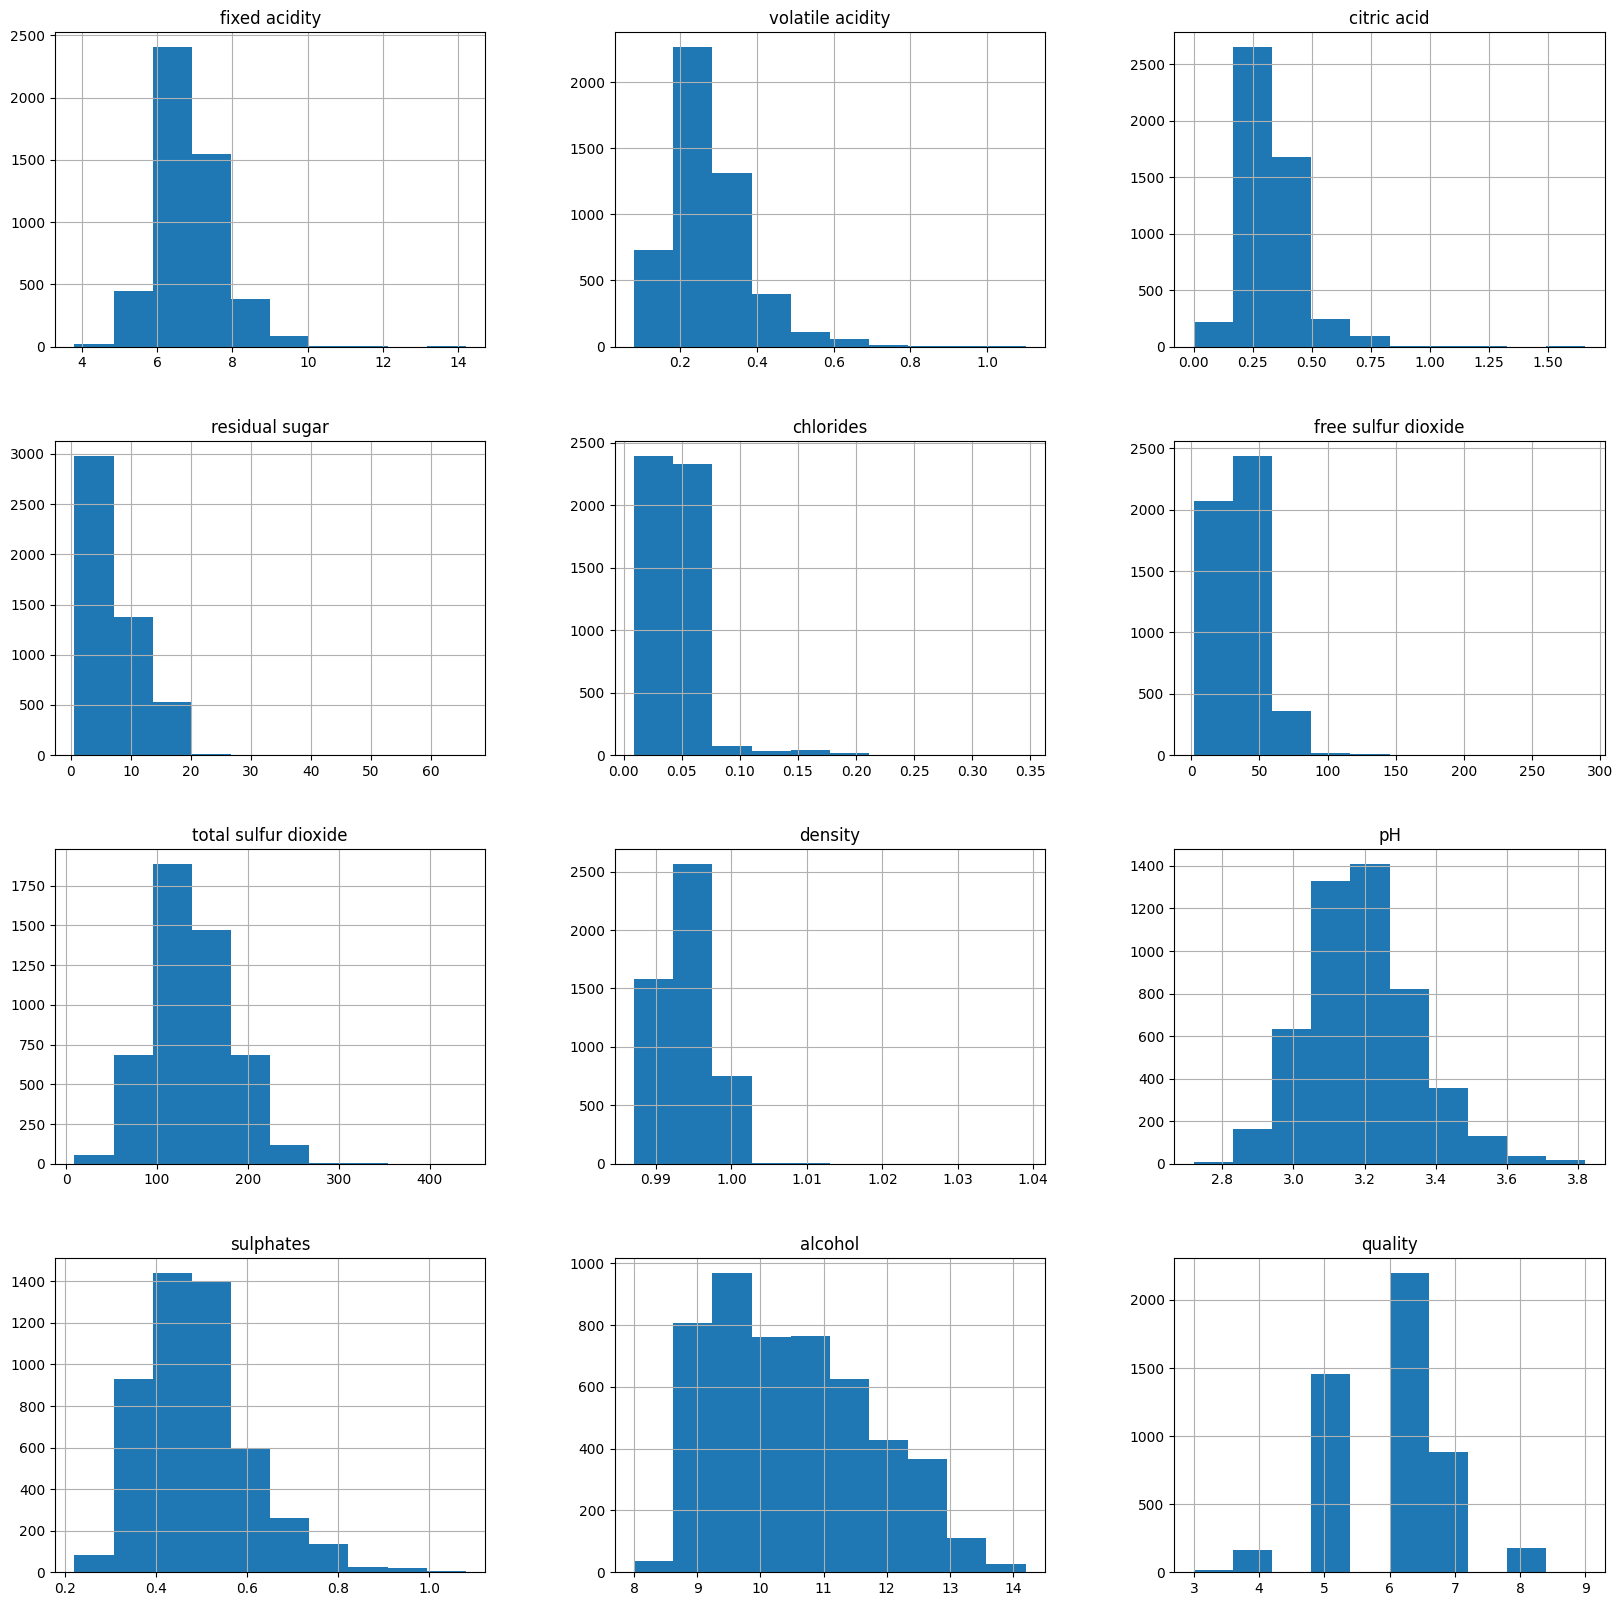

In [5]:
data.hist(figsize=(20, 20))

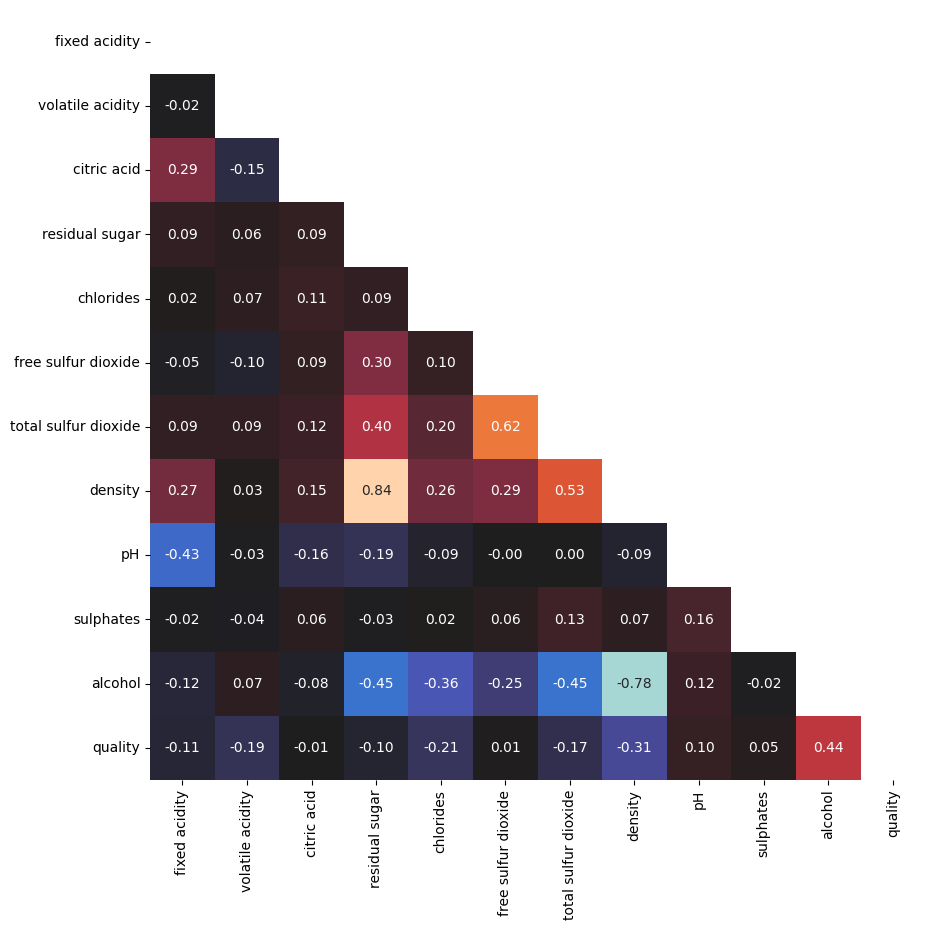

In [6]:
plt.figure(figsize=(10,10))

corr_matrix = data.corr()
lower = corr_matrix.where(np.tril(np.ones(corr_matrix.shape), k=-1).astype(bool))

sns.heatmap(lower, annot=True, fmt='.2f', cbar=False, center=0);

In [7]:
high_corr = [
    column for column in lower.columns if any((lower[column] > 0.6)|(lower[column] < -0.6))
]
high_corr

['residual sugar', 'free sulfur dioxide', 'density']

In [8]:
other_features = [col for col in data.columns if col not in high_corr and col!='quality']

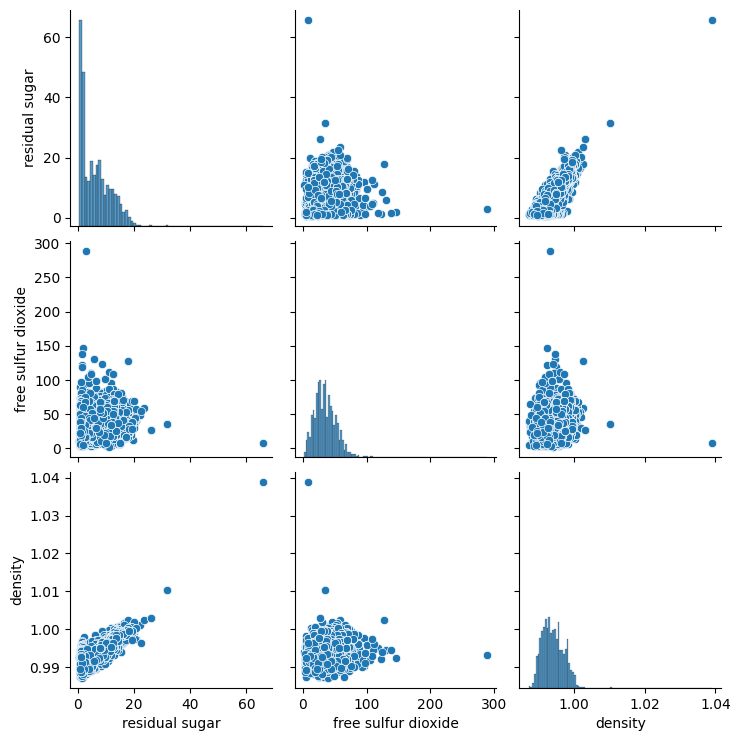

In [9]:
sns.pairplot(data[high_corr]);

## Простой метод

### 3-$\sigma$ (правило трех сигм)


In [10]:
def outlier_std(data, col, threshold=3):
    mean = data[col].mean()
    std = data[col].std()
    up_bound = mean + threshold * std
    low_bound = mean - threshold * std
    anomalies = (data[col] > up_bound) | (data[col] < low_bound)  # Создаем логическую маску напрямую
    return anomalies, up_bound, low_bound

In [11]:
def get_column_outliers(data, columns=None, function=outlier_std, threshold=3):
    if columns:
        columns_to_check = columns
    else:
        columns_to_check = data.columns

    outliers = pd.Series(data=[False]*len(data), index=data.index, name='is_outlier')  # Используем data.index
    comparison_table = {}
    for column in columns_to_check:
        anomalies, upper_bound, lower_bound = function(data, column, threshold=threshold)
        comparison_table[column] = [upper_bound, lower_bound, sum(anomalies), 100*sum(anomalies)/len(anomalies)]

        # Используем булеву индексацию с .loc
        outliers.loc[data.index[anomalies]] = True

    comparison_table = pd.DataFrame(comparison_table).T
    comparison_table.columns=['upper_bound', 'lower_bound', 'anomalies_count', 'anomalies_percentage']
    comparison_table = comparison_table.sort_values(by='anomalies_percentage', ascending=False)

    return comparison_table, outliers

def anomalies_report(outliers):
    print("Total number of outliers: {}\nPercentage of outliers:   {:.2f}%".format(
            sum(outliers), 100*sum(outliers)/len(outliers)))

In [12]:
data_features = data.iloc[:, :-1]

In [13]:
comparison_table, std_outliers = get_column_outliers(data_features)
anomalies_report(std_outliers)

Total number of outliers: 396
Percentage of outliers:   8.08%


In [14]:
comparison_table

,upper_bound,lower_bound,anomalies_count,anomalies_percentage
chlorides,0.111316,-0.019772,102.0,2.082483
citric acid,0.697251,-0.028868,85.0,1.735402
volatile acidity,0.580625,-0.024143,81.0,1.653736
sulphates,0.832224,0.147469,48.0,0.979992
fixed acidity,9.386392,4.323183,46.0,0.939159
pH,3.641268,2.735265,32.0,0.653328
free sulfur dioxide,86.329497,-15.713327,32.0,0.653328
total sulfur dioxide,265.854851,10.866464,12.0,0.244998
residual sugar,21.607588,-8.824758,9.0,0.183748
density,1.003000,0.985055,3.0,0.061249


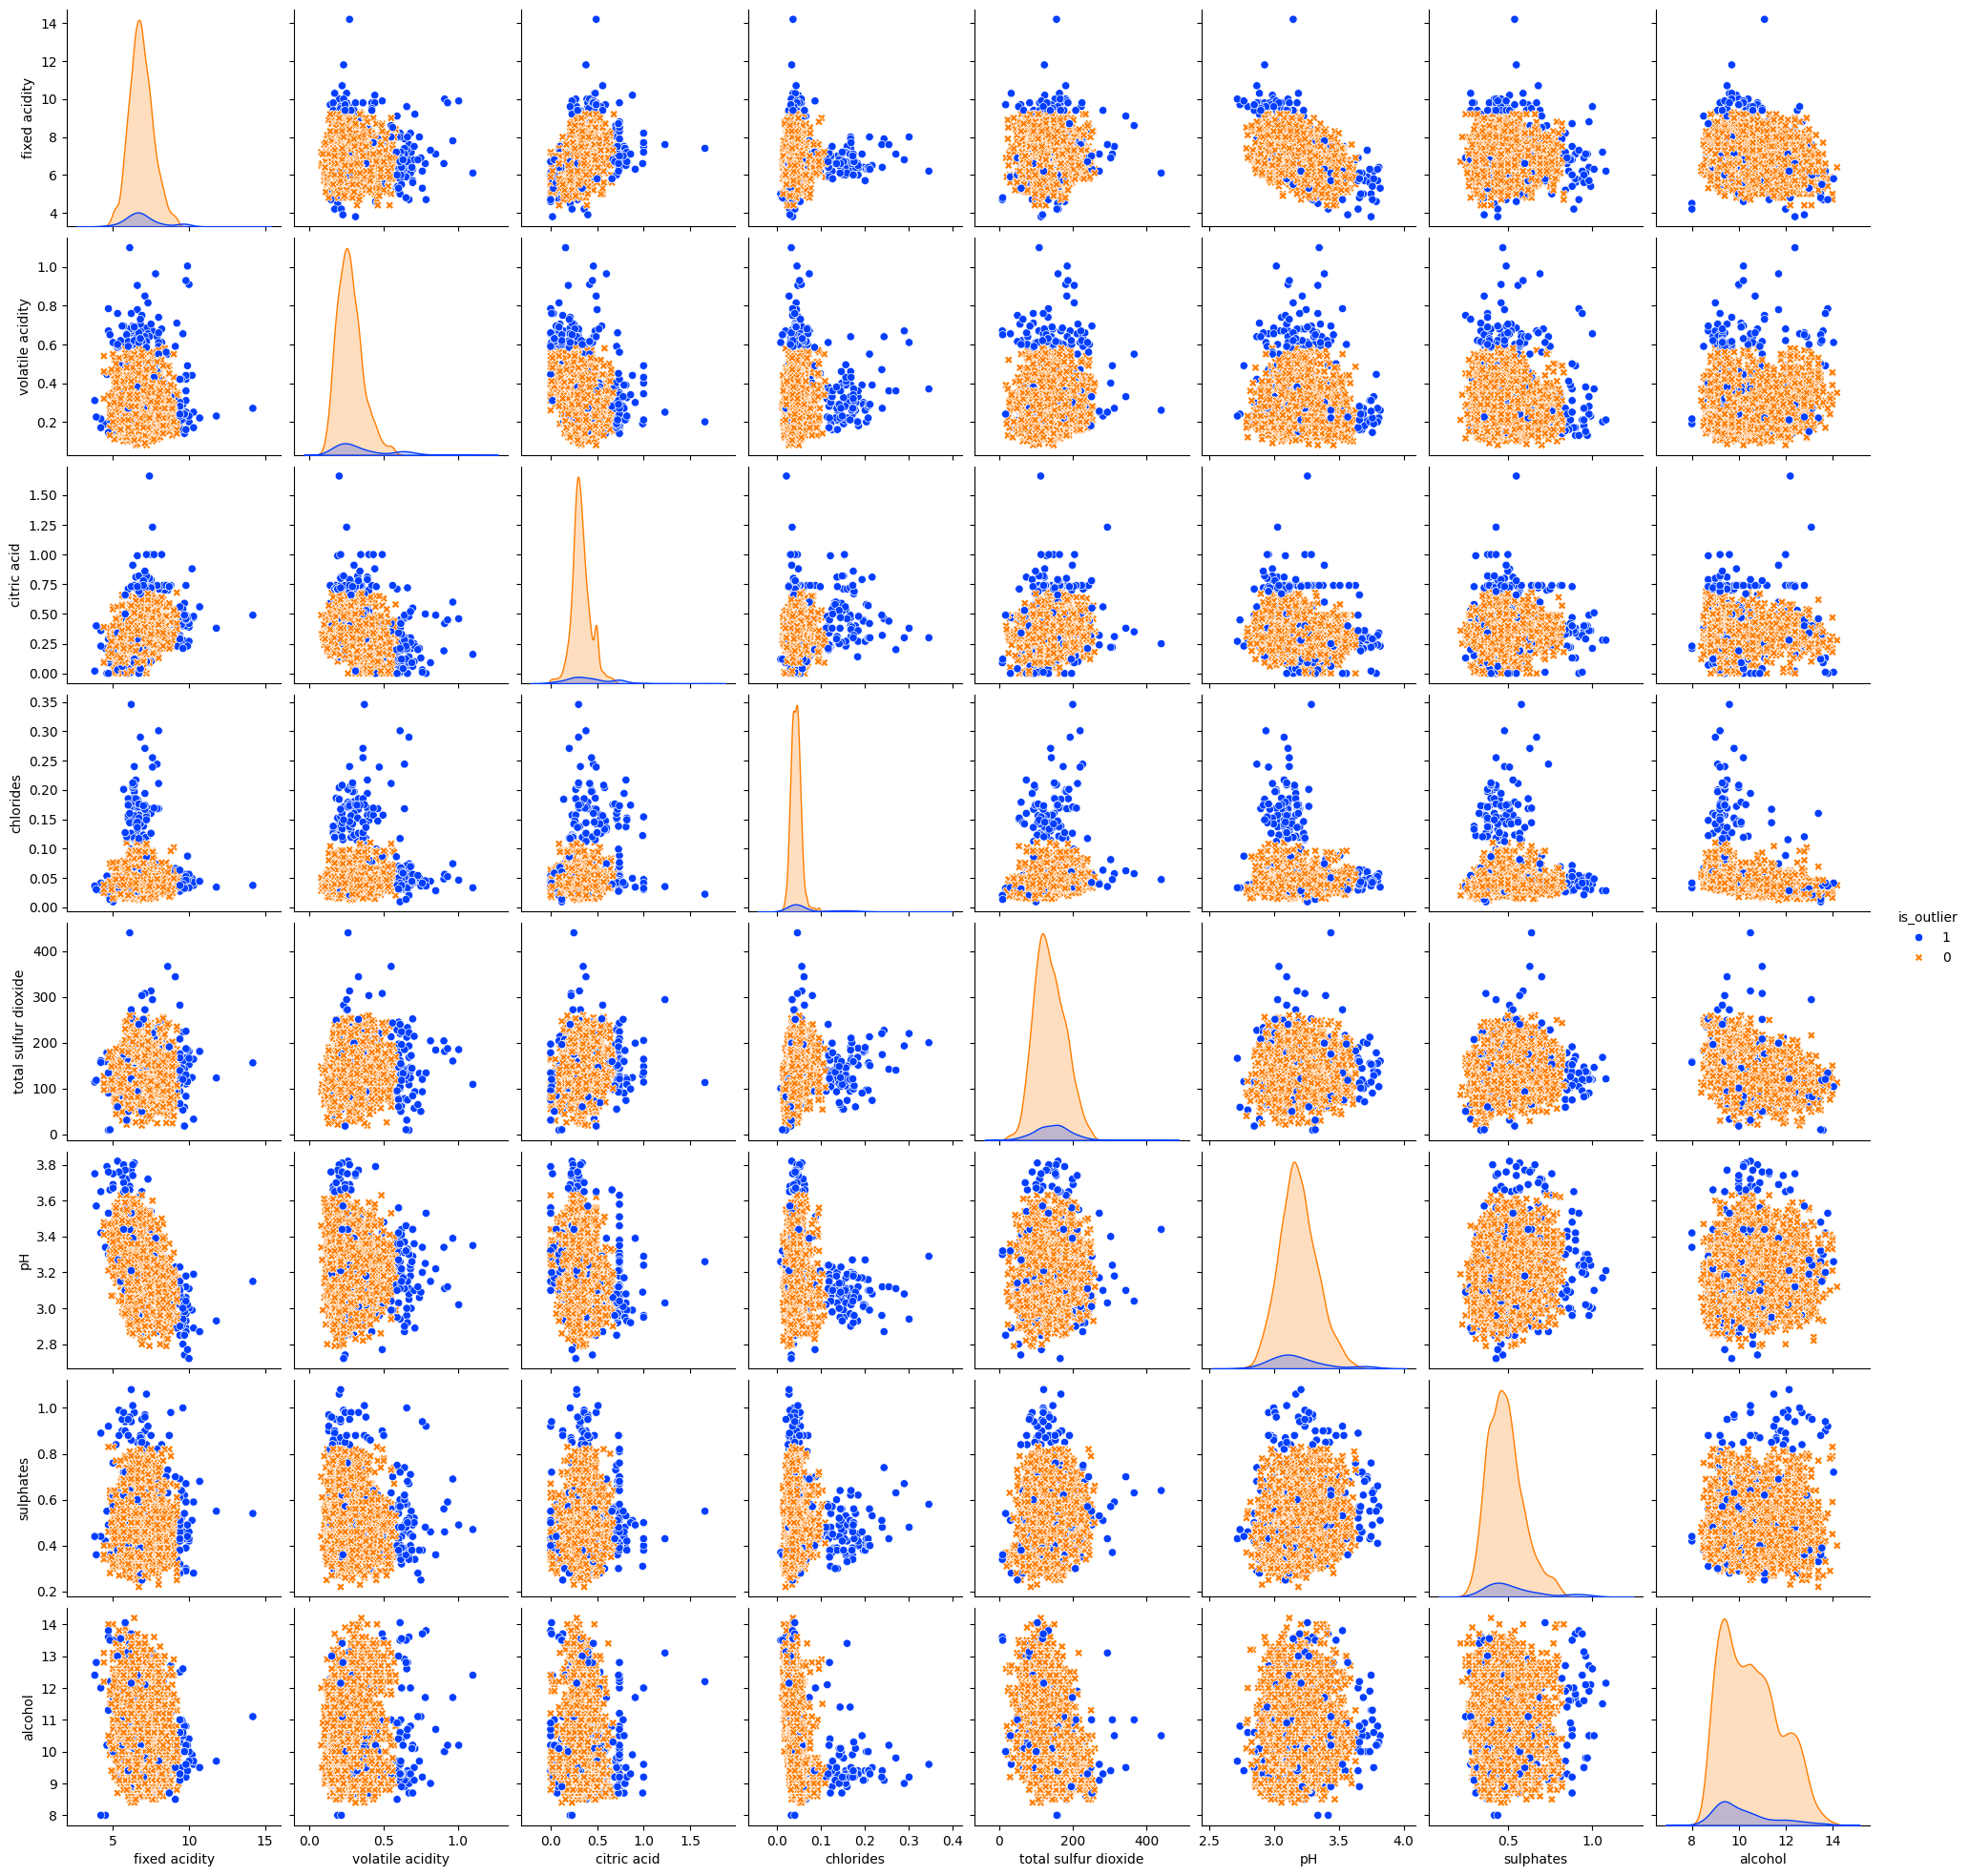

In [15]:
# ~55 сек
labeled_data = data_features.copy()
labeled_data['is_outlier'] = std_outliers

sns.pairplot(data=labeled_data, vars = other_features,
             hue='is_outlier', hue_order=[1, 0],
             markers=['X', 'o'],  palette='bright');

# Обнаружение аномалий


`Scikit-learn` имеет несколько алгоритмов обнаружения аномалий. Их описание и примеры приведены на [этой странице](https://scikit-learn.org/stable/modules/outlier_detection.html).

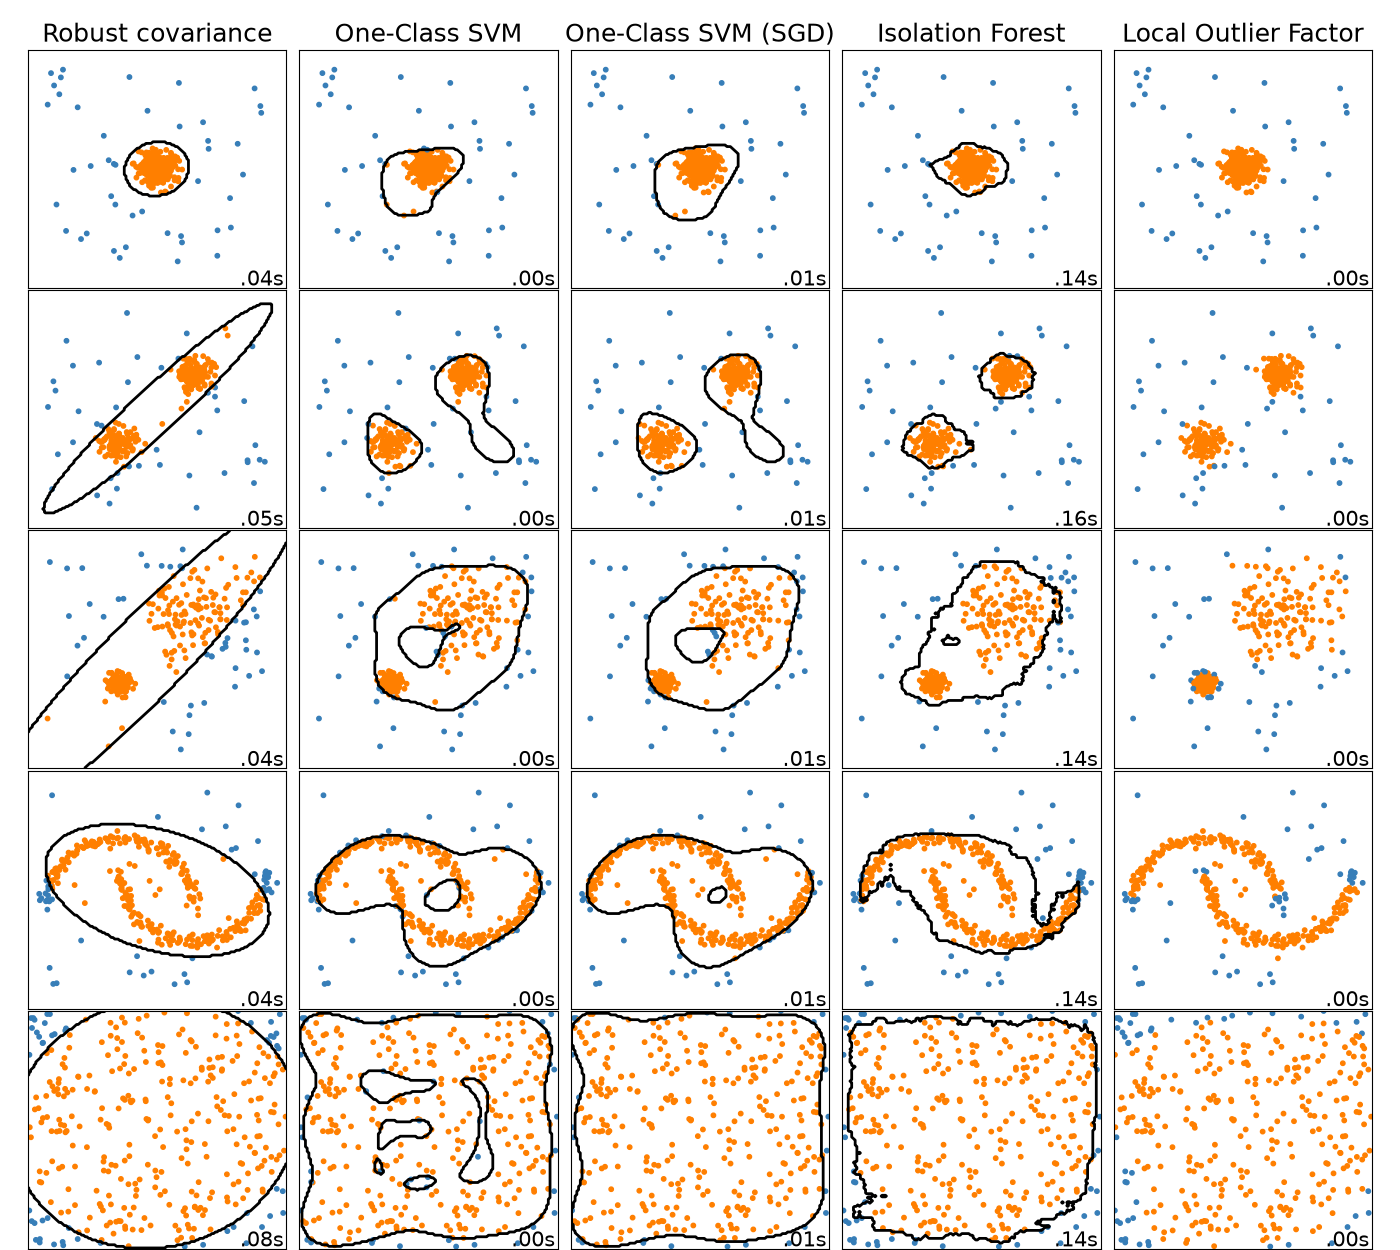


## Метод опорных векторов одного класса (One-class SVM) <a id="one-class_svm"></a>


## Кратко о методе опорных векторов (SVM)

В двух словах, SVM — это базовая линейная модель. Основная идея алгоритма (в задаче классификации) заключается в разделении классов гиперплоскостью таким образом, чтобы максимизировать расстояние (зазор) между ними. Изначально алгоритм мог работать только с линейно разделимыми классами, однако в 90-х годах прошлого века метод приобрёл особую популярность благодаря введению «Kernel Trick» (ядрового трюка) (1992), позволившего эффективно работать с линейно неразделимыми данными.

![](https://sandipanweb.files.wordpress.com/2018/04/svm_slack.png?w=676)

## Ядровой трюк (Kernel Trick)

Ядро — это функция, которая может преобразовывать пространство признаков (в том числе нелинейно), без непосредственного преобразования самих признаков.

Это крайне эффективно с точки зрения вычислений и потенциально позволяет получать бесконечномерные пространства признаков.

Идея состоит в том, что классы, которые линейно неразделимы в текущем пространстве признаков, могут стать разделимыми в пространствах более высокой размерности:

![](https://miro.medium.com/max/1838/1*eU9PzjVcLNbNEzBC2g_iWg.jpeg)

## Метод опорных векторов одного класса
Хорошая [статья](https://scikit-learn.org/stable/auto_examples/svm/plot_oneclass.html) с объяснением.

**Метод опорных векторов одного класса (One Class SVM)** — это одна из форм классического алгоритма, однако, как следует из названия, для его обучения нам нужен только один класс, пусть даже немного «зашумлённый», и мы хотим научиться определять для каждого нового наблюдения, является ли оно аномальным или нет.

**Основная идея:** преобразовать пространство признаков и провести разделяющую гиперплоскость так, чтобы наблюдения находились как можно дальше от начала координат:

![](https://www.researchgate.net/profile/Hany_Alashwal/publication/242572058/figure/fig1/AS:393295319584771@1470780319210/Classification-in-one-class-SVM.png)

В результате мы получаем границу, по одну сторону которой находятся наиболее «плотные» и похожие между собой наблюдения из обучающей выборки, а по другую — аномальные значения, не похожие на остальные. Долю таких аномальных наблюдений, которые модель будет стараться отделить от основной части выборки, мы задаём в самом начале обучения с помощью параметра `nu`


In [16]:
from sklearn.preprocessing import RobustScaler
scaler = RobustScaler()
scaled_data = pd.DataFrame(
    data=scaler.fit_transform(data_features),
    columns=data_features.columns
)

In [17]:
from sklearn.svm import OneClassSVM

one_class_svm = OneClassSVM(nu=0.10, gamma='auto')
one_class_svm.fit(scaled_data)
svm_outliers = one_class_svm.predict(scaled_data)
svm_outliers = np.array([1 if label == -1 else 0 for label in svm_outliers])

In [18]:
anomalies_report(svm_outliers)

Total number of outliers: 499
Percentage of outliers:   10.19%


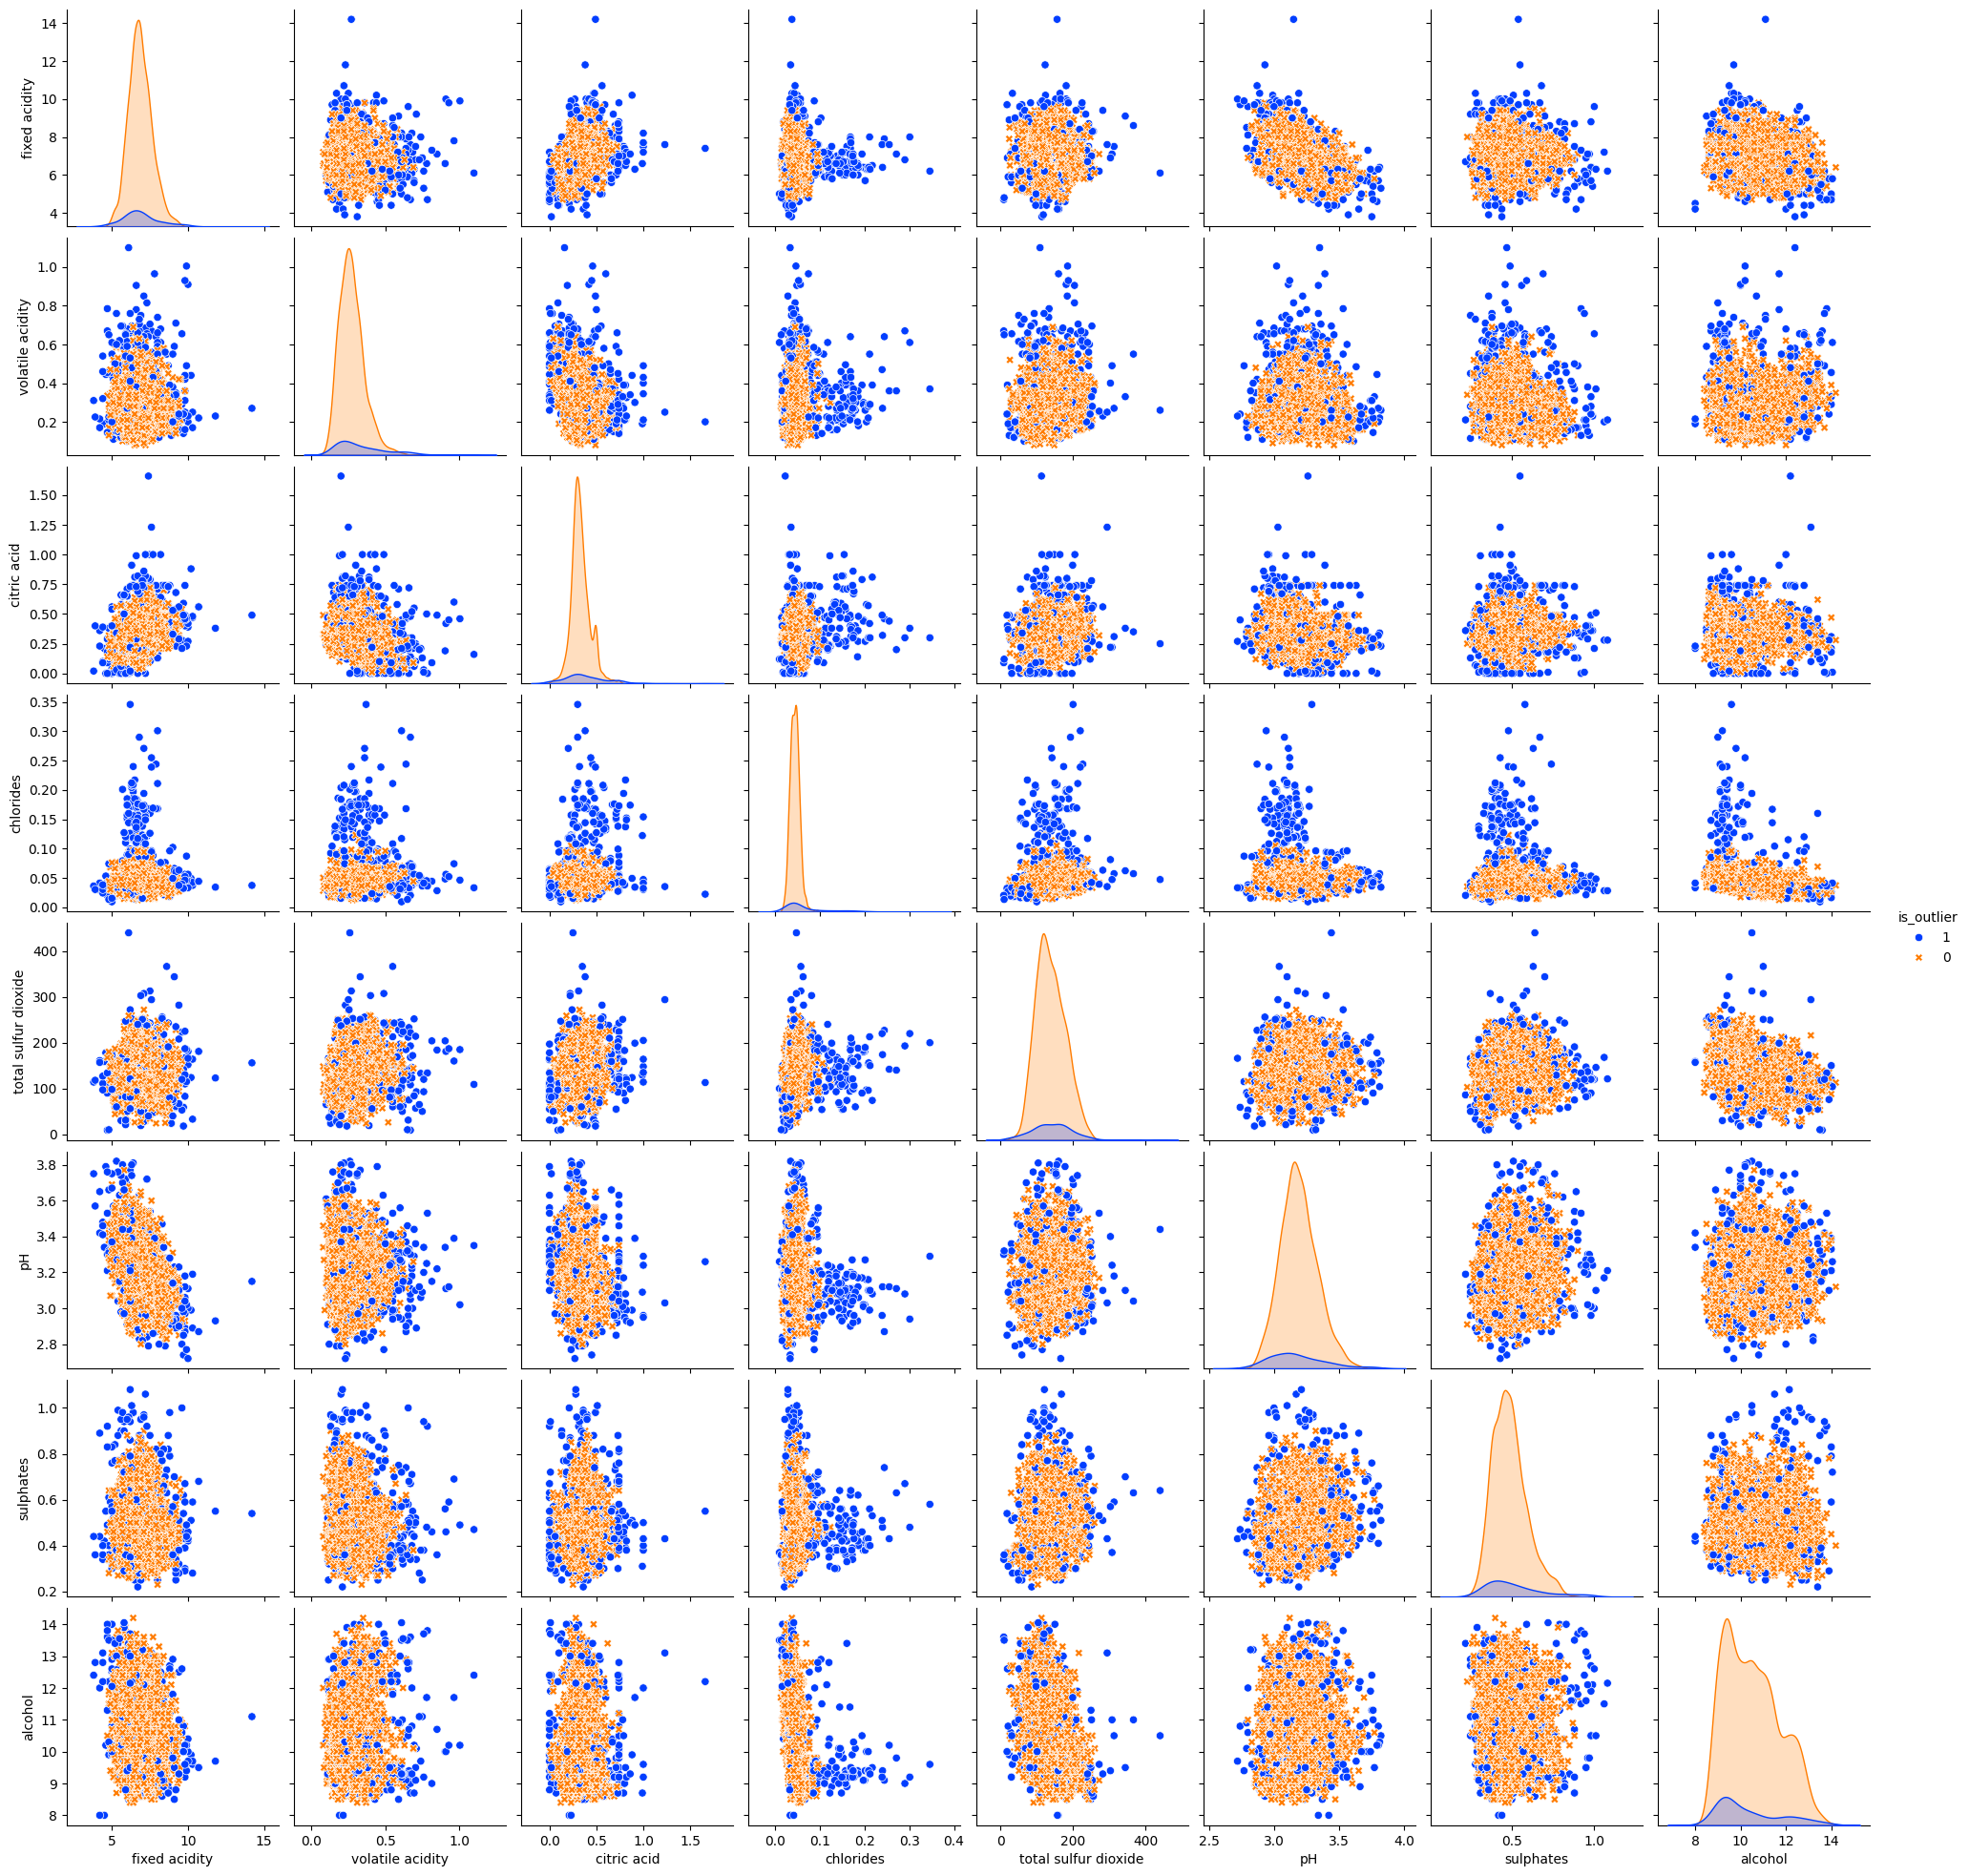

In [19]:
# ~51 сек
labeled_data = data_features.copy()
labeled_data['is_outlier'] = svm_outliers

sns.pairplot(data=labeled_data, vars = other_features,
             hue='is_outlier', hue_order=[1, 0],
             markers=['X', 'o'],  palette='bright');

## Достоинства и недостатки

\+ Благодаря ядровому трюку модель способна строить **нелинейные разделяющие границы**

\+ Особенно удобно использовать, когда в данных недостаточно «плохих» наблюдений для применения стандартного подхода обучения с учителем — бинарной классификации

\- Может сильно **переобучаться** и давать большое количество ложноотрицательных результатов, если зазор разделения слишком мал


## Изолирующий лес (Isolation Forest) <a id="isolation_forest"></a>


## <center> Изолирующий лес (Isolation Forest) </center>

Идея — посмотрим, насколько легко «изолировать» наблюдение от всех остальных. Если это слишком легко, вероятно, оно находится далеко и является выбросом. Если очень сложно — скорее всего, оно похоже на множество других точек и выбросом не является.


**Алгоритм:**
1. Выбрать точку для изоляции.
2. Для каждого признака установить диапазон изоляции между минимальным и максимальным значением.
3. Выбрать признак случайным образом.
4. Выбрать значение из диапазона случайным образом:
    - Если точка больше выбранного значения, сдвинуть минимальный диапазон признака до этого значения.
    - Если точка меньше — сдвинуть максимальное значение признака до этого значения.
5. Повторять шаги 3 и 4, пока точка не будет изолирована. То есть пока точка не окажется единственной в диапазоне по всем признакам.
6. Подсчитать количество повторений шагов 3 и 4.

Хорошая [статья](https://quantdare.com/isolation-forest-algorithm/) с объяснением.


In [20]:
from sklearn.ensemble import IsolationForest

isolation_forest = IsolationForest(n_estimators=100, contamination=0.1,
                                   max_features=1.0, bootstrap=True)
isolation_forest.fit(scaled_data)

isolation_outliers = isolation_forest.predict(scaled_data)
isolation_outliers = np.array([1 if label == -1 else 0 for label in isolation_outliers])

In [21]:
anomalies_report(isolation_outliers)

Total number of outliers: 490
Percentage of outliers:   10.00%


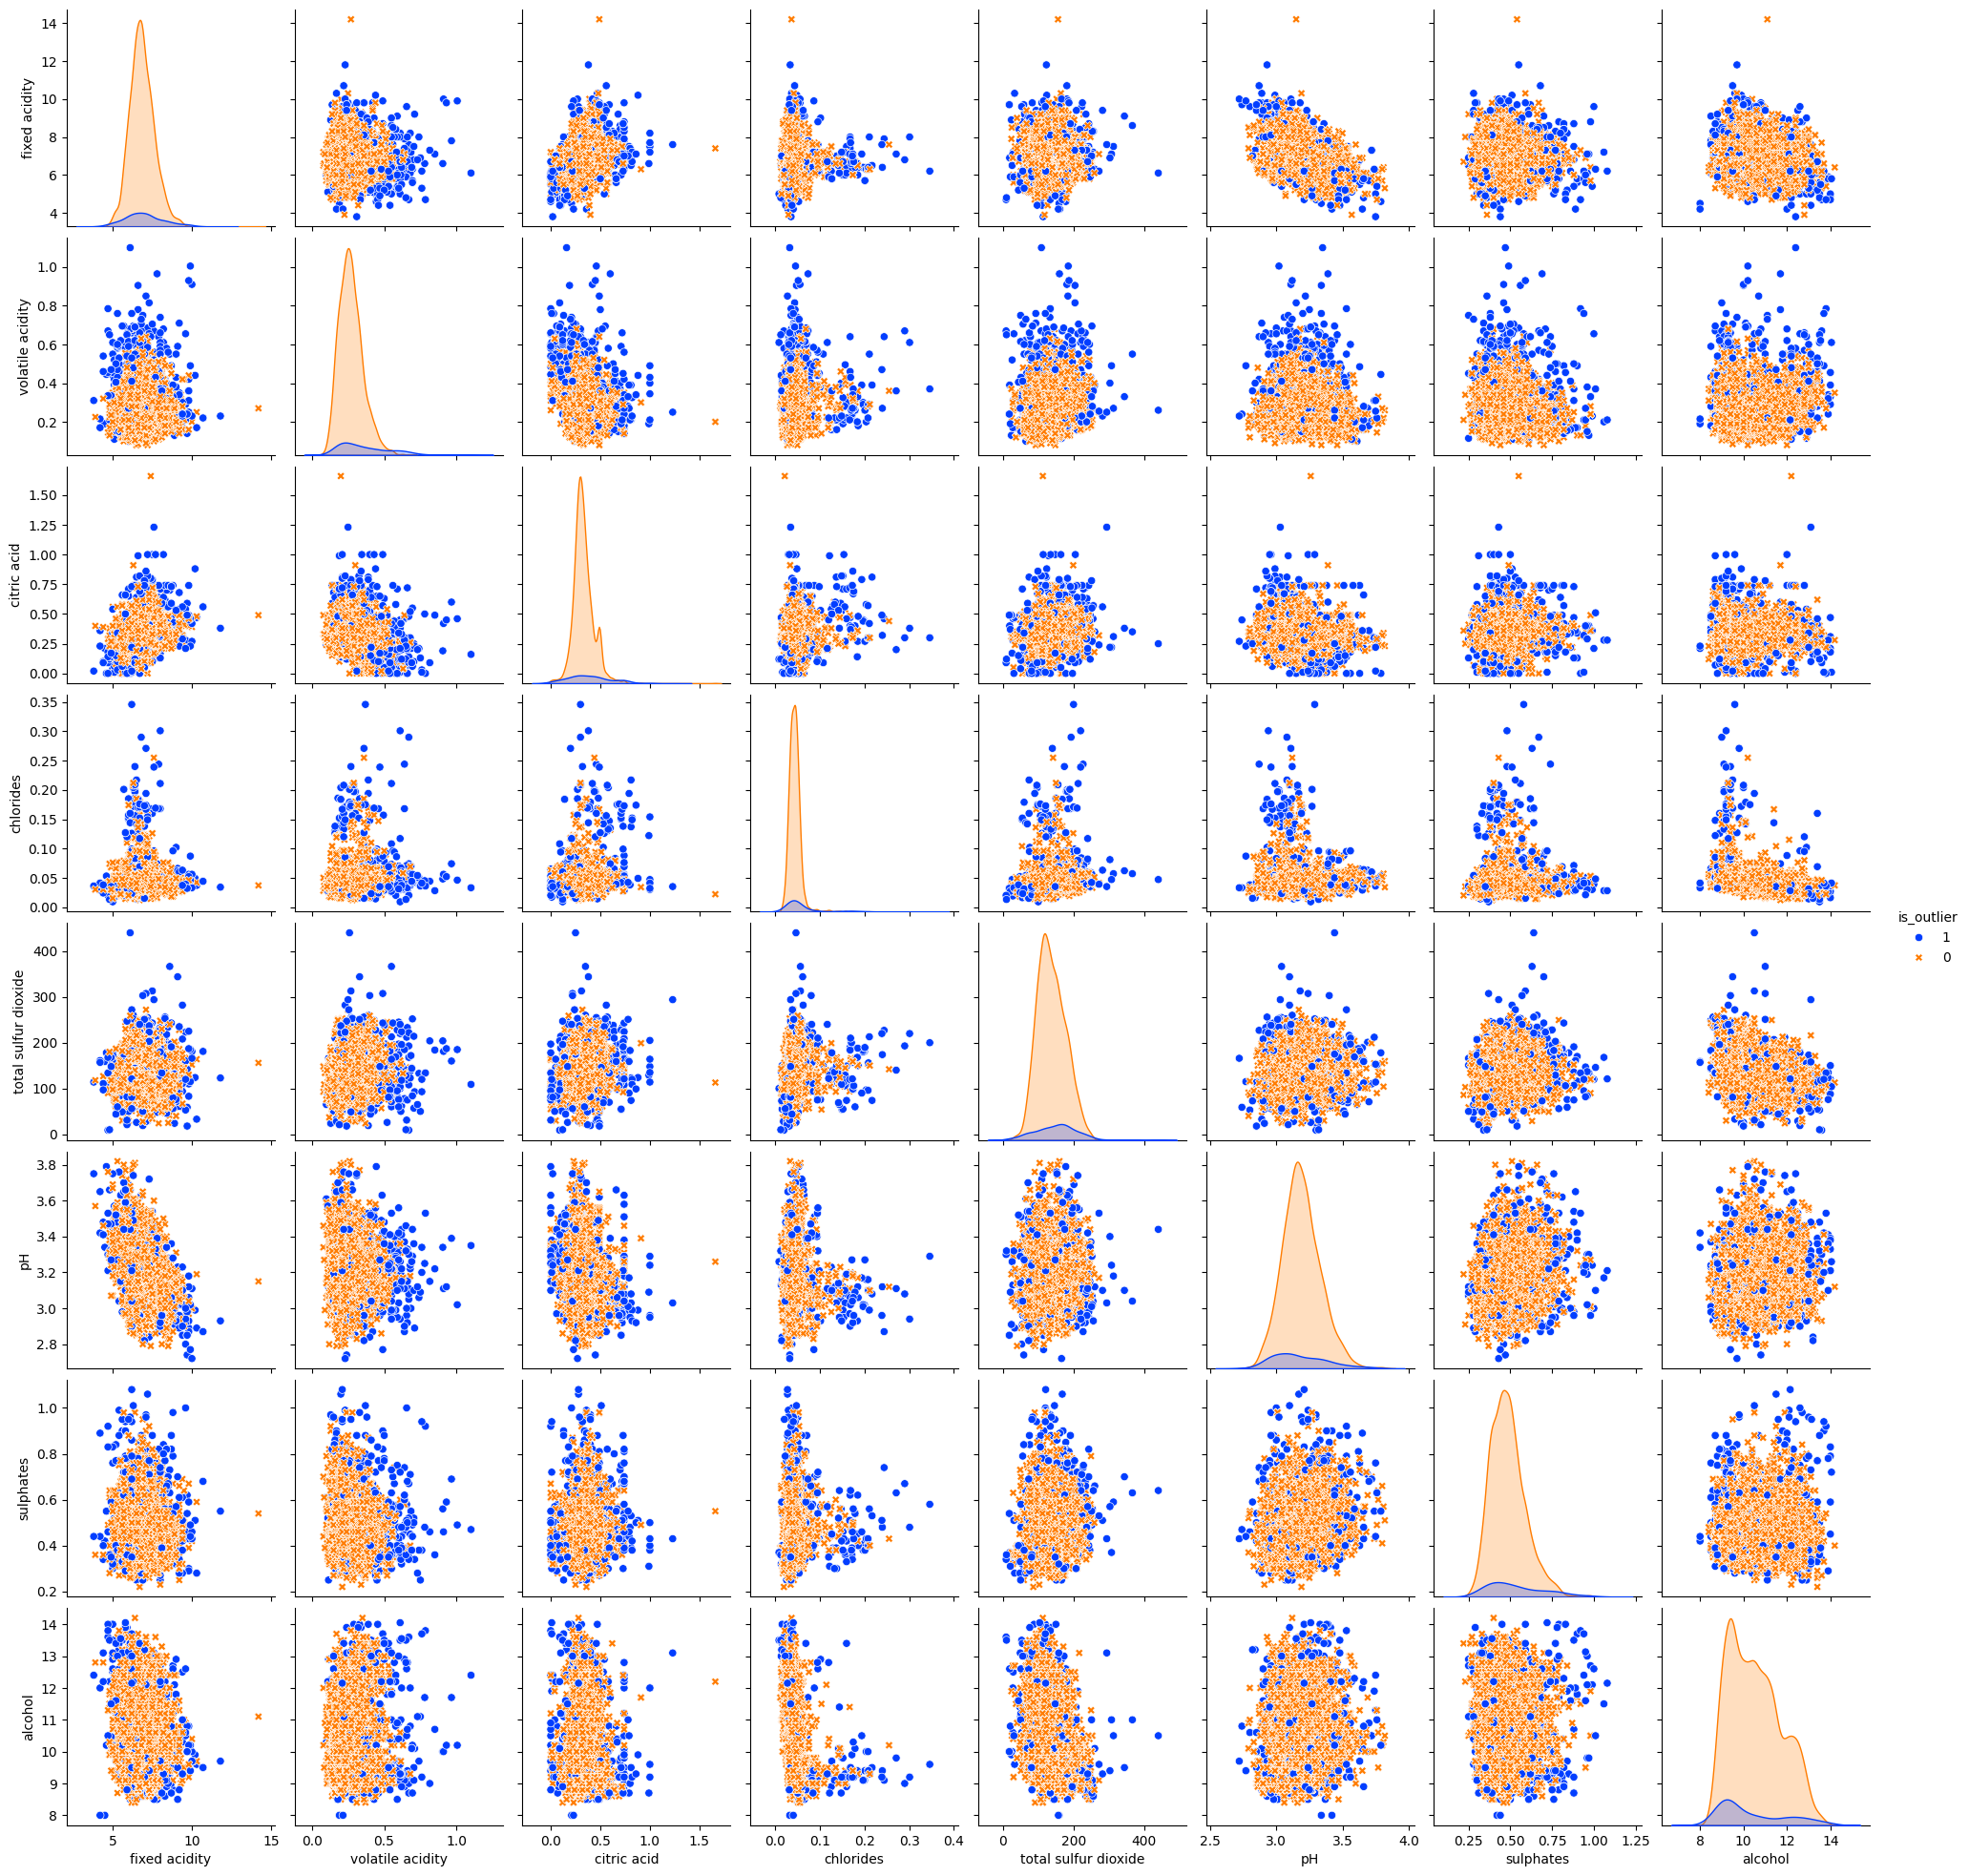

In [22]:
# ~48 сек
labeled_data = data_features.copy()
labeled_data['is_outlier'] = isolation_outliers

sns.pairplot(data=labeled_data, vars = other_features,
             hue='is_outlier', hue_order=[1, 0],
             markers=['X', 'o'],  palette='bright');

## Достоинства и недостатки

\+ **Нелинейные разделяющие границы**, интуитивно понятные принципы работы

\+ Удобно использовать, когда нельзя перейти к бинарной классификации

\- Довольно сложная настройка параметров, которую трудно провести без хотя бы минимальной разметки или предположения о количестве «загрязнённых» наблюдений — параметр `contamination`


## CUSUM <a id="cumsum"></a>


[Обнаружение изменений](http://en.wikipedia.org/wiki/Change_detection) (Change detection) относится к процедурам выявления резких изменений в каком-либо явлении (Basseville и Nikiforov, 1993; Gustafsson, 2000). Под резким изменением понимается любое отклонение от предыдущих известных данных, происходящее быстрее ожидаемого, по такой характеристике данных, как амплитуда, среднее, дисперсия, частота и т. д.

Алгоритм [кумулятивной суммы (CUSUM)](http://en.wikipedia.org/wiki/CUSUM) — классический метод мониторинга изменений. Одна из форм реализации алгоритма CUSUM предполагает вычисление кумулятивных сумм положительных и отрицательных изменений ($g_t^+$ и $g_t^-$) в данных ($x$) и сравнение с $threshold$ (порогом). При превышении порога обнаруживается изменение ($t_{talarm}$), и кумулятивная сумма сбрасывается до нуля. Чтобы избежать обнаружения изменения при его отсутствии или при медленном дрейфе, алгоритм также зависит от параметра $drift$ для коррекции. Данная форма алгоритма CUSUM задаётся следующим образом:

$$ \begin{array}{l l}
\left\{ \begin{array}{l l}
s[t] = x[t] - x[t-1] \\
g^+[t] = max\left(g^+[t-1] + s[t]-drift,\; 0\right) \\
g^-[t] = max\left(g^-[t-1] - s[t]-drift,\; 0\right)
\end{array} \right. \\
\\
\; if \;\;\; g^+[t] > threshold \;\;\; or \;\;\;  g^-[t] > threshold: \\
\\
\left\{ \begin{array}{l l}
t_{talarm}=t \\
g^+[t] = 0 \\
g^-[t] = 0
\end{array} \right.
\end{array} $$

<!-- TEASER_END -->

Существуют различные реализации алгоритма CUSUM; например, слагаемое суммы последних элементов ($s[t]$ выше) может иметь более длинную историю (с фильтрацией), может быть нормализовано путём вычитания среднего и деления на дисперсию, или это слагаемое может быть возведено в квадрат для обнаружения изменений как дисперсии, так и параметров и т. д.

Для корректной работы алгоритма CUSUM необходимо настроить параметры $h$ и $v$ в соответствии с тем, что считается изменением в данных. Согласно Gustafsson (2000), настройка может выполняться по следующим шагам:

 - Начать с очень большого $threshold$ (порога).  
 - Выбрать $drift$ равным половине ожидаемого изменения, или настроить $drift$ так, чтобы $g$ = 0 более 50% времени.  
 - Затем установить $threshold$ так, чтобы обеспечить требуемое количество ложных срабатываний (это можно сделать автоматически) или задержку обнаружения.  
 - Если требуется более быстрое обнаружение, попробовать уменьшить $drift$.  
 - Если нужно меньше ложных срабатываний, попробовать увеличить $drift$.  
 - Если часть моментов изменений не имеет смысла, попробовать увеличить $drift$.


In [23]:
!pip install detecta

Функция `detect_cusum.py` из Python-модуля `detecta` реализует алгоритм CUSUM и процедуру вычисления конца обнаруженного изменения. Сигнатура функции:   

```python
ta, tai, taf, amp = detect_cusum(x, threshold=1, drift=0, ending=False, show=True, ax=None)
```   

Посмотрим, как использовать `detect_cusum.py`; сначала импортируем необходимые библиотеки Python и настроим окружение:


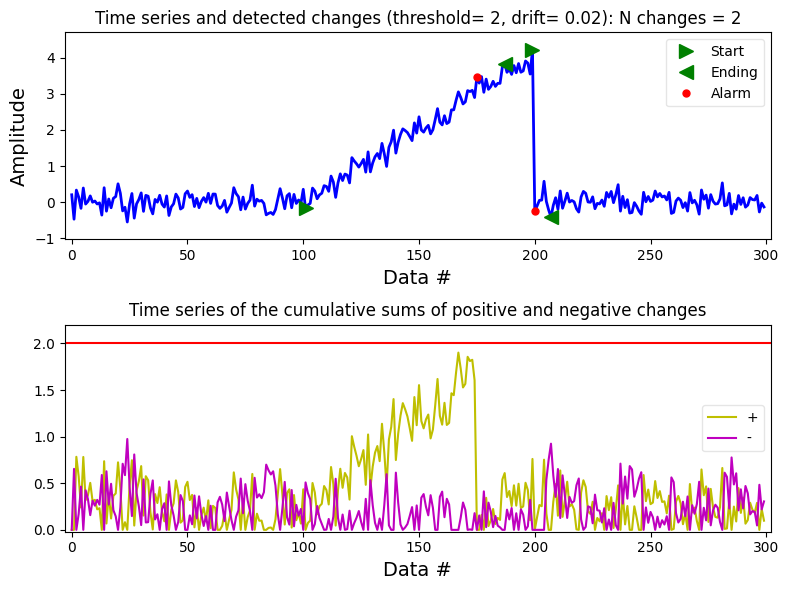

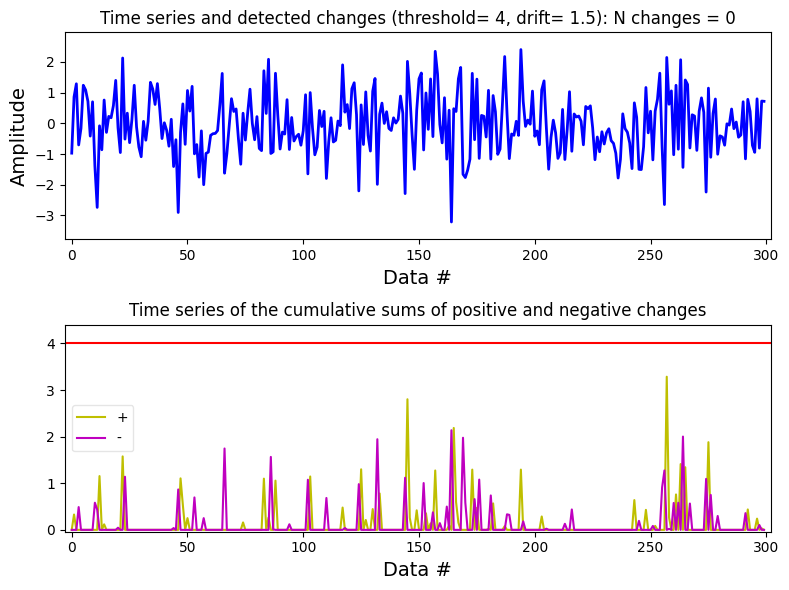

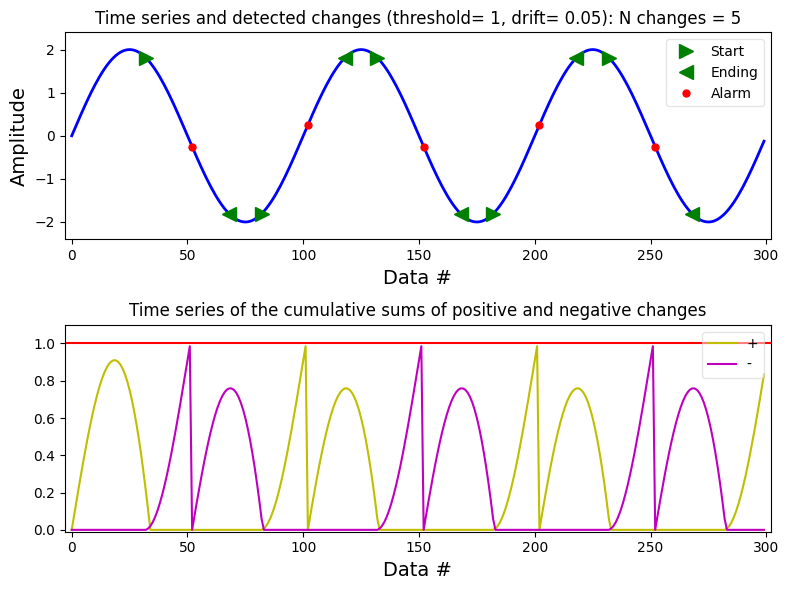

In [24]:
from detecta import detect_cusum

x = np.random.randn(300)/5
x[100:200] += np.arange(0, 4, 4/100)
ta, tai, taf, amp = detect_cusum(x, 2, .02, True, True)

x = np.random.randn(300)
detect_cusum(x, 4, 1.5, True, True)

x = 2*np.sin(2*np.pi*np.arange(0, 3, .01))
ta, tai, taf, amp = detect_cusum(x, 1, .05, True, True)

## Производительность функции

Вот простой тест производительности `detect_cusum.py`:


In [25]:
x = np.random.randn(10000)
x[400:600] += 6
print('Detection of onset (data size = %d):' %x.size)
%timeit detect_cusum(x, 4, 1.5, True, False)

Detection of onset (data size = 10000):
53.8 ms ± 11.1 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


## Ссылки

- Michèle Basseville and Igor V. Nikiforov (1993). [Detection of Abrupt Changes: Theory and Application](http://books.google.com.br/books/about/Detection_of_abrupt_changes.html?id=Vu5SAAAAMAAJ). Prentice-Hall.   
- Fredrik Gustafsson (2000) [Adaptive Filtering and Change Detection](http://books.google.com.br/books?id=cyNTAAAAMAAJ). Wiley.


## k-Means <a id="k-means"></a>


Алгоритм k-средних — простой и элегантный подход для разбиения набора данных на $K$ различных непересекающихся кластеров. Для выполнения кластеризации методом k-средних необходимо сначала задать желаемое число кластеров $K$; затем алгоритм отнесёт каждое наблюдение ровно к одному из $K$ кластеров.


Введём некоторые обозначения. Пусть $C_1, ..., C_K$ — множества, содержащие индексы наблюдений каждого кластера. Эти множества удовлетворяют двум свойствам:
1. Каждое наблюдение принадлежит хотя бы одному из $K$ кластеров.
2. Кластеры не пересекаются: ни одно наблюдение не принадлежит более чем одному кластеру.


Идея алгоритма k-средних состоит в том, что хорошая кластеризация — это та, при которой внутрикластерная дисперсия минимальна. Внутрикластерная дисперсия для кластера $C_k$ — это мера $W(C_k)$, показывающая, насколько наблюдения внутри кластера отличаются друг от друга. Таким образом, мы хотим решить задачу $$\sum_{k=1}^K W(C_k) \to \min_{C_k}.$$ Иными словами, требуется разбить наблюдения на $K$ кластеров так, чтобы суммарная внутрикластерная дисперсия, суммированная по всем $K$ кластерам, была минимальной.

Чтобы сделать это операционным, необходимо определить внутрикластерную дисперсию. Существует много способов её определить, однако наиболее распространённым является квадратичное евклидово расстояние. А именно, определим $$W(C_k) = \frac{1}{|C_k|}\sum_{i,i'\in C_k}\sum_{j=1}^p\left(x_{ij}-x_{i'j}\right)^2.$$ Иными словами, внутрикластерная дисперсия для $k$-го кластера — это сумма всех попарных квадратичных евклидовых расстояний между наблюдениями в $k$-м кластере, делённая на общее число наблюдений в этом кластере.


### Подготовка данных


In [26]:
n_samples = 1500
random_state = 170

#игрушечные датасеты
X_blobs, y_blobs = datasets.make_blobs(centers=3, n_samples=n_samples, random_state=random_state, center_box=(-10, 10))
X_circles, y_circles = datasets.make_circles(n_samples=n_samples, factor=.5, noise=.05)
X_moons, y_moons = datasets.make_moons(n_samples=n_samples, noise=.05)

In [27]:
X_blobs[:5], X_circles[:5], X_moons[:5]

(array([[ -5.19811282,   0.64186932],
        [ -5.75229538,   0.41862711],
        [-10.84489837,  -7.55352273],
        [ -4.57098483,  -0.80101741],
        [ -3.51916215,   0.0393449 ]]),
 array([[ 1.04509346,  0.21374496],
        [-0.77574361, -0.66686717],
        [ 0.96657992,  0.31618131],
        [-0.3550297 ,  0.36164983],
        [ 0.09274372, -0.46121009]]),
 array([[-0.44256133,  0.84596706],
        [ 0.03230003,  0.31103911],
        [-0.6037191 ,  0.8851335 ],
        [-0.31363422,  0.86776999],
        [ 1.81863286, -0.04854709]]))

In [28]:
y_blobs[:10]

array([1, 1, 0, 1, 1, 2, 0, 0, 0, 2])

In [29]:
def plot_clusters(X, y):

    # Создать график нестандартного размера
    # plt.figure(figsize=(6, 4))

    if y is not None:
        for cluster_label in np.unique(y):
            # Нарисовать все объекты с y == i (класс 0)
            plt.scatter(X[y == cluster_label, 0],     # выбирает все объекты с y == i и 1-м столбцом X
                        X[y == cluster_label, 1],     # выбирает все объекты с y == i и 2-м столбцом X
                        label=str(cluster_label))     # метка для легенды
    else:
        plt.scatter(X[:, 0], X[:, 1], label='samples')

    plt.xlabel('X1', size=12) # настройка метки по оси X
    plt.ylabel('X2', size=12) # настройка метки по оси Y
    plt.xticks(size=12)
    plt.yticks(size=12)

    plt.legend(loc='best', fontsize=12) # создание легенды и установка ее положения
    plt.grid() # создает сетку на графике

    plt.show()

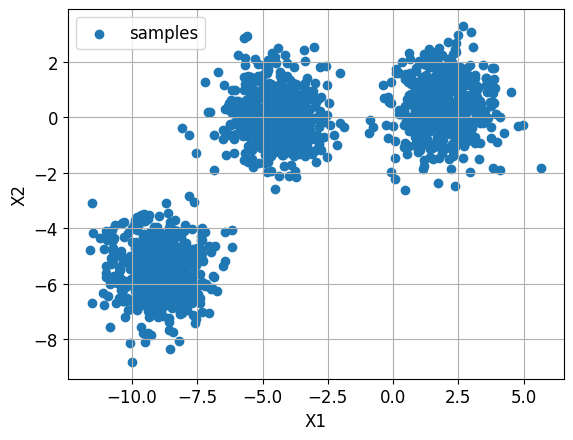

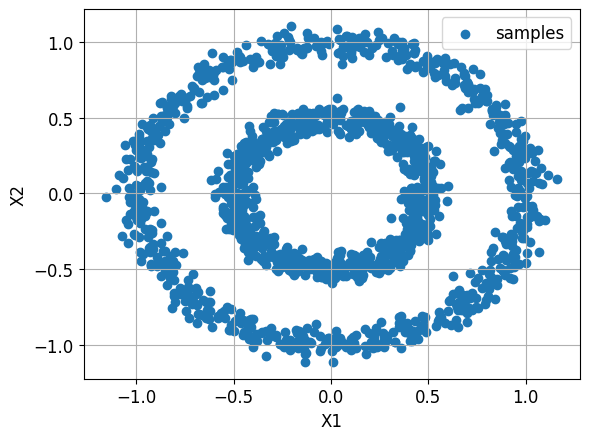

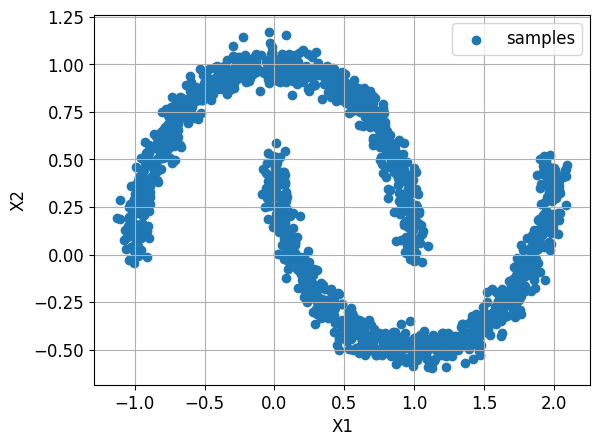

In [30]:
plot_clusters(X_blobs, y=None)
plot_clusters(X_circles, y=None)
plot_clusters(X_moons, y=None)

### Алгоритм k-Means:


In [31]:
#реализация k-Means из sklearn
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, max_iter=20, n_init=10)
kmeans.fit(X_blobs)
y_pred_blobs = kmeans.predict(X_blobs)

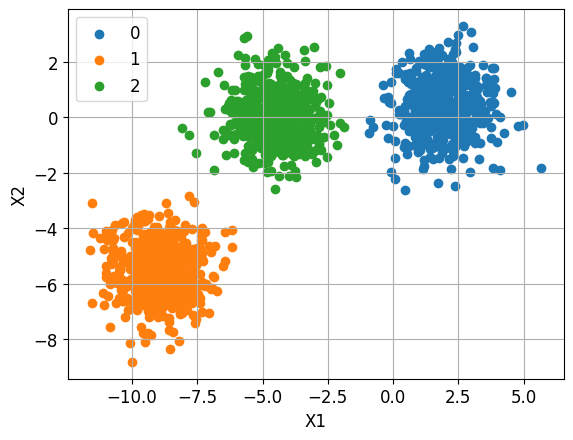

In [32]:
plot_clusters(X_blobs, y_pred_blobs)

In [33]:
kmeans = KMeans(n_clusters=2, max_iter=20, n_init=10)
kmeans.fit(X_circles)
y_pred_circles = kmeans.predict(X_circles)

kmeans = KMeans(n_clusters=2, max_iter=20, n_init=10)
kmeans.fit(X_moons)
y_pred_moons = kmeans.predict(X_moons)

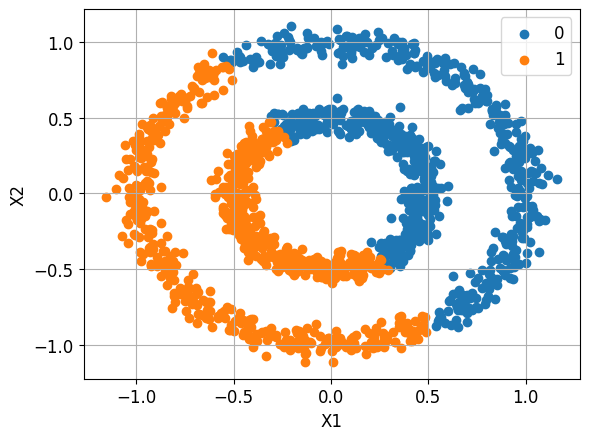

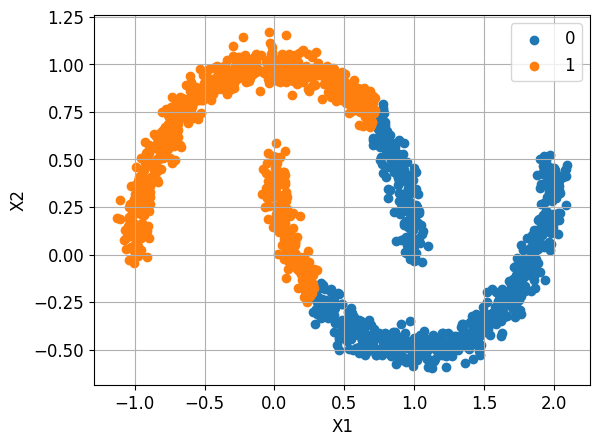

In [34]:
plot_clusters(X_circles, y_pred_circles)
plot_clusters(X_moons, y_pred_moons)

k-Means плохо работает в данном примере. Нам нужен другой алгоритм кластеризации. Какой?


## Метрики

**Коэффициент силуэта (Silhouette Score):**

$$
s = \frac{b - a}{max(a, b)}
$$

- **a**: Среднее расстояние между объектом и всеми остальными точками того же кластера.
- **b**: Среднее расстояние между объектом и всеми точками ближайшего соседнего кластера.

Силуэтный коэффициент для набора данных — это среднее значение, вычисленное по всем наблюдениям.


**Скорректированный индекс Рэнда (Adjusted Rand Index, ARI):**

$$
ARI = \frac{RI - Expected\_RI}{max(RI) - Expected\_RI}
$$

$$
RI = \frac{a + b}{a + b + c + d}
$$


- a — количество пар элементов из S, находящихся в одном подмножестве в X и в одном подмножестве в Y
- b — количество пар элементов из S, находящихся в разных подмножествах в X и в разных подмножествах в Y
- c — количество пар элементов из S, находящихся в одном подмножестве в X и в разных подмножествах в Y
- d — количество пар элементов из S, находящихся в разных подмножествах в X и в одном подмножестве в Y


In [35]:
from sklearn import metrics

silhouette_score_values = []
adjusted_rand_score_values = []
n_clusters = np.arange(2, 21)

for n in n_clusters:

    clusterer = KMeans(n_clusters=n, max_iter=10, n_init=10)
    clusterer.fit(X_blobs)
    y_pred = clusterer.predict(X_blobs)

    score1 = metrics.silhouette_score(X_blobs, y_pred)
    silhouette_score_values.append(score1)

    score2 = metrics.adjusted_rand_score(y_blobs, y_pred)
    adjusted_rand_score_values.append(score2)

In [36]:
y_blobs

array([1, 1, 0, ..., 2, 2, 2], shape=(1500,))

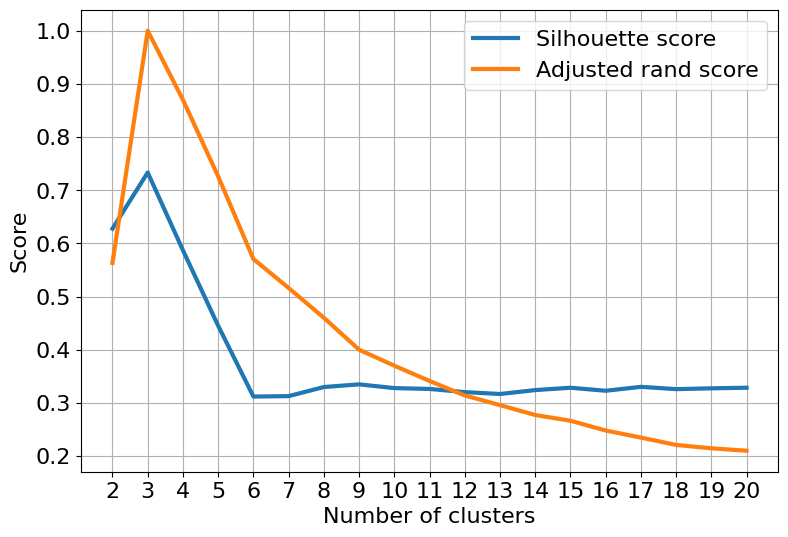

In [37]:
plt.figure(figsize=(9, 6))
plt.plot(n_clusters, silhouette_score_values, linewidth=3, label='Silhouette score')
plt.plot(n_clusters, adjusted_rand_score_values, linewidth=3, label='Adjusted rand score')
plt.xlabel('Number of clusters', size=16)
plt.ylabel('Score', size=16)
plt.xticks(n_clusters, size=16)
plt.yticks(size=16)
plt.legend(loc='best', fontsize=16)
plt.grid()
plt.show()

## DBSCAN <a id="dbscan"></a>



Алгоритм DBSCAN:
- 1. Выбрать случайную непосещённую точку и найти её соседей в заданной окрестности
- 2. Если соседей меньше критического значения, назвать их выбросами
- 3. Если нет — объединить в «плотный» кластер и повторить поиск соседей
- 4. Если все плотные точки пройдены и помечены как посещённые — выбрать новую непосещённую точку и начать заново

Красивая визуализация DBSCAN — [здесь](https://www.naftaliharris.com/blog/visualizing-dbscan-clustering/).


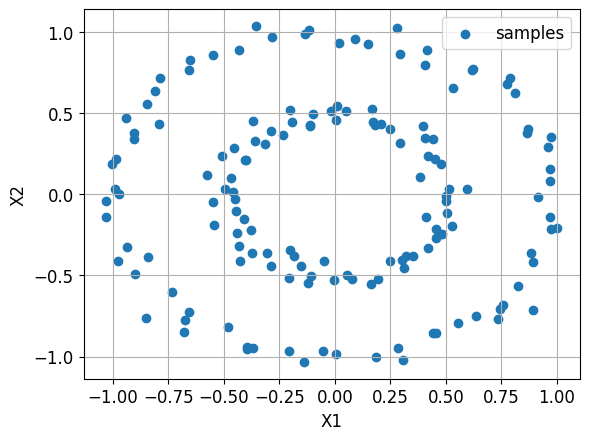

In [38]:
from sklearn import datasets

n_samples = 150
random_state = 170
#X, y = datasets.make_blobs(centers=3, n_samples=n_samples, random_state=random_state, center_box=(-10, 10))

X, y = datasets.make_circles(n_samples=n_samples, factor=.5, noise=.05)
# X, y = datasets.make_moons(n_samples=n_samples, noise=.05)
# X = np.random.rand(n_samples, 2)

plot_clusters(X, None)

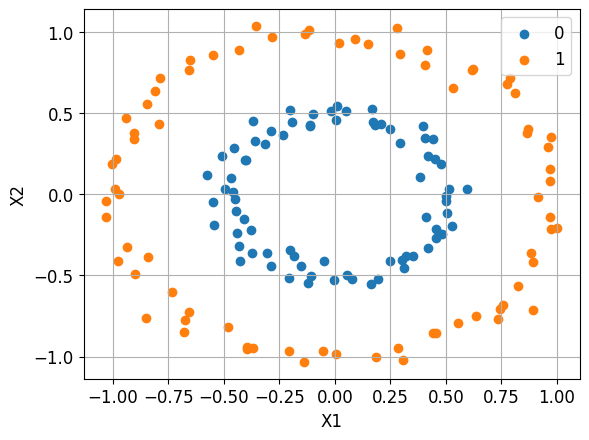

In [39]:
# DBSCAN
from sklearn import cluster

# Запустить кластеризатор
clusterer = cluster.DBSCAN(eps=0.25, min_samples=5)
y_pred = clusterer.fit_predict(X)

# Построить результаты кластеризации
plot_clusters(X, y_pred)

Как правильно выбрать параметры алгоритма DBSCAN?


In [40]:
from sklearn.neighbors import NearestNeighbors

k = 5

# Оценить k ближайших соседей для каждой точки в X
nn = NearestNeighbors(n_neighbors=k)
nn.fit(X)

# Вычислить расстояния для каждого из k ближайших соседей
dists, _ = nn.kneighbors(X, n_neighbors=k)

# Взять расстояния только до k-го соседа
dist_kth = dists[:, k-1]

# Отсортировать расстояния
dist_kth.sort()

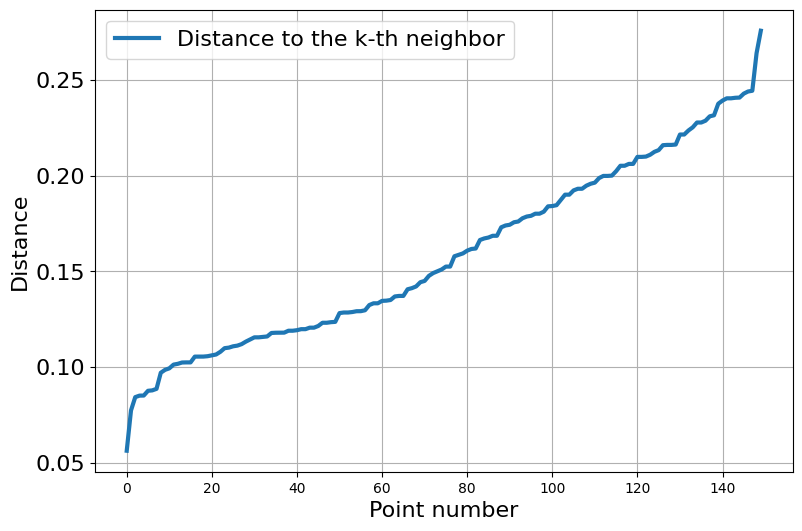

In [41]:
plt.figure(figsize=(9, 6))
plt.plot(dist_kth, linewidth=3, label='Distance to the k-th neighbor')
plt.xlabel('Point number', size=16)
plt.ylabel('Distance', size=16)
plt.yticks(size=16)
plt.legend(loc='best', fontsize=16)
plt.grid()
plt.show()

## Иерархическая кластеризация

Иерархическая кластеризация — один из популярных и простых для понимания методов кластеризации.

Данный метод делится на два типа:
1. Агломеративный (алгоритм объединяет два меньших кластера в один на каждой итерации)
2. Дивизивный (алгоритм разделяет один кластер на два меньших на каждой итерации)

Рассмотрим агломеративную иерархическую кластеризацию (дивизивная рассматривается по аналогии).

**Агломеративная иерархическая кластеризация:**
В данном методе изначально каждый объект данных рассматривается как отдельный кластер. На каждой итерации похожие кластеры объединяются с другими, пока не останется один кластер или K кластеров.

Базовый алгоритм агломеративной кластеризации прост:
1. Вычислить матрицу близости
2. Считать каждую точку данных отдельным кластером
3. **Повтор:** объединить два наиближайших кластера и обновить матрицу близости
4. До тех пор, пока не останется единственный кластер

Резюме:
1. Можно выбрать любое число кластеров, остановив алгоритм в нужный момент
2. Этот алгоритм значительно менее чувствителен к выбору метрики между точками, чем другие

Иерархическую кластеризацию удобно визуализировать с помощью дендрограммы.



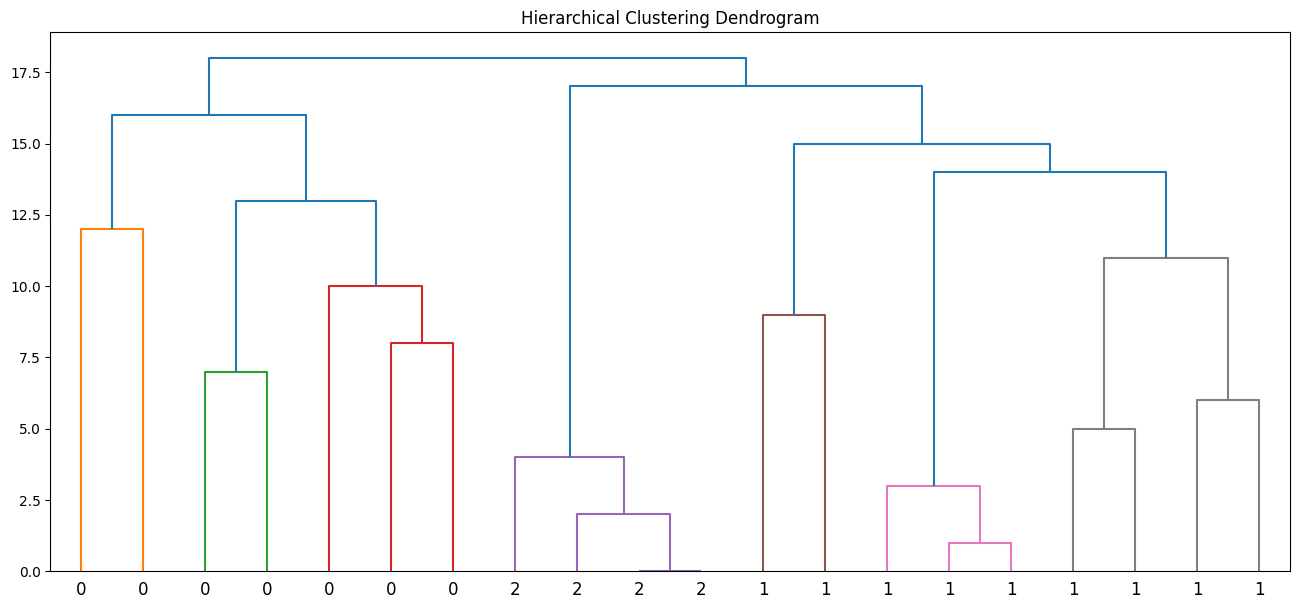

In [42]:
from scipy.cluster.hierarchy import dendrogram
from sklearn.datasets import load_iris
from sklearn.cluster import AgglomerativeClustering

def plot_dendrogram(model, **kwargs):

    # Дочерние элементы иерархической кластеризации
    children = model.children_

    # Расстояния между каждой парой дочерних элементов
    # Поскольку у нас нет этой информации, можно использовать равномерную шкалу для построения
    distance = np.arange(children.shape[0])

    # Количество наблюдений в каждом уровне кластера
    no_of_observations = np.arange(2, children.shape[0]+2)

    # Создать матрицу связей и построить дендрограмму
    # формат матрицы связей: https://docs.scipy.org/doc/scipy/reference/generated/scipy.cluster.hierarchy.linkage.html#scipy.cluster.hierarchy.linkage
    linkage_matrix = np.column_stack([children, distance, no_of_observations]).astype(float)

    # Построить соответствующую дендрограмму
    dendrogram(linkage_matrix, **kwargs)


iris = load_iris()
X = iris.data[:20]
model = AgglomerativeClustering(n_clusters=3)

model = model.fit(X)
plt.figure(figsize=(16,7))
plot_dendrogram(model, labels=model.labels_)
plt.title('Hierarchical Clustering Dendrogram')
plt.show()